# 01. 랭그래프 이해하기.ipyng의 목적
 - 노드, 엣지의 이해임
 
# Part 1. 그래프제작 샘플 & TypedDict로 State 정의
① 그래프 틀 만들기 → ② 노드 등록 → ③ 화살표 연결 → ④ 완성(compile)
- 질문(question)이 들어오면 
- classify 분류함수를 갖고 있는 정의된 node에 가 '환불' 또는 '일반'으로 분류해 intent에 적고
- respond 답변함수를 갖고 있는 정의된 node노드가 intent를 보고 답을 answer에 적는다
    -  환불 → "환불 규정을 안내해 드리겠습니다."
    - 일반 → "무엇을 도와드릴까요?"
- 최종 결과로 question, intent, answer가 모두 채워진 State가 나온다



In [3]:
#! python.exe -m pip install --upgrade pip
! pip install -q langgraph

In [23]:
# 분류노드 만들기
def classify(state):
    q = state["question"]                 # state에서 질문 읽기
    if "환불" in q:
        return {"intent": "환불"}         # intent 칸 채우기
    else:
        return {"intent": "일반"}

# 답변노드 만들기
def respond(state):
    if state["intent"] == "환불":         # 앞 노드가 채운 칸 읽기
        return {"answer": "환불 규정을 안내해 드리겠습니다."}
    else:
        return {"answer": "무엇을 도와드릴까요?"}

# 함수 실행해서 보기
print(classify({"question": "환불 규정 알려주세요"}))
print(respond({"question": "환불 규정 알려주세요", "intent": "환불"}))

{'intent': '환불'}
{'answer': '환불 규정을 안내해 드리겠습니다.'}


# - State : 노드들이 같이 쓰는 메모장
        - 그래프 안에는 일하는 노드가 여러 개 있습니다.
        - 노드들은 서로 직접 말하지 않습니다.
        - 대신 메모장 한 장을 돌려 가며 씁니다.
        - 각 노드는 메모장을 읽고, 자기 할 일을 적고, 다음 노드에게 넘깁니다.
        - 마지막 노드까지 돌고 나면, 다 채워진 메모장이 결과입니다.
    - 노드는 state 전체를 받는다
    - 노드는 바꿀 key만 돌려준다. 돌려주지 않은 key는 그대로 남는다
    - State가 하는 일 세 가지
        - 노드 사이의 전달 통로: 노드는 State를 받고, 바꿀 칸만 돌려줍니다.
        - 흐름을 정하는 근거: 조건 분기는 State에 적힌 값(예: intent)을 보고 다음 노드를 고릅니다.
        - 의 단위: 메모리(checkpointer)를 붙이면 저장되는 것이 바로 이 State입니다. 대화 기억도 State 안의 messages를 저장하는 것입니다.

In [24]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

# 함수들이 쓰는 칸: question, intent, answer
class State(TypedDict):
    question: str    # 질문 칸
    intent: str      # 분류 칸
    answer: str      # 답변 칸
    
builder = StateGraph(State)
print(builder.nodes)
print("\n ------------------ builder node start")

{}

 ------------------ builder node start


- builder.nodes                      (dict)
    └─ "node_classify"                (노드 이름)
         └─ StateNodeSpec              (노드 설정표)
             └─ runnable               (RunnableCallable: 함수를 감싼 부품)
                 └─ func = classify    (원래 함수)

In [25]:
# 노드등록
builder.add_node("node_classify", classify)    # 노드 이름, 함수
builder.add_node("node_respond", respond)

print(list(builder.nodes))




['node_classify', 'node_respond']


In [26]:
# 엣지연결
builder.add_edge(START, "node_classify")          # 시작 → 분류
builder.add_edge("node_classify", "node_respond") # 분류 → 답변
builder.add_edge("node_respond", END)             # 답변 → 끝

print(sorted(builder.edges))

[('__start__', 'node_classify'), ('node_classify', 'node_respond'), ('node_respond', '__end__')]


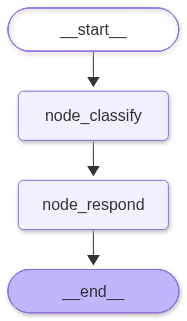

In [27]:
# compile
graph = builder.compile()
graph

In [28]:
# 실행
print(graph.invoke({"question": "환불 규정 알려주세요"}))
print(graph.invoke({"question": "안녕하세요"}))

{'question': '환불 규정 알려주세요', 'intent': '환불', 'answer': '환불 규정을 안내해 드리겠습니다.'}
{'question': '안녕하세요', 'intent': '일반', 'answer': '무엇을 도와드릴까요?'}


In [29]:
# 앞에서는 classify 결과를 respond에 직접 넣어 줬습니다. 
# 질문만 넣으면 그래프가 메모장을 넘겨줘서, 세 칸이 모두 채워진 결과가 나옵니다.
result = graph.invoke({"question": "환불규정 알려주세요"})
print(result["answer"])

환불 규정을 안내해 드리겠습니다.


In [33]:
# 노드추가, answer 칸을 읽어서 뒤에 인사말을 붙이는 노드입니다.
def polite(state):
    return {"answer": state["answer"] + " 바람길여행을 이용해 주셔서 감사합니다."}

print(builder.nodes.keys())

dict_keys(['node_classify', 'node_respond'])


Adding an edge to a graph that has already been compiled. This will not be reflected in the compiled graph.
Adding an edge to a graph that has already been compiled. This will not be reflected in the compiled graph.


['node_classify', 'node_respond', 'node_polite']
{'question': '환불 규정 알려주세요', 'intent': '환불', 'answer': '환불 규정을 안내해 드리겠습니다. 바람길여행을 이용해 주셔서 감사합니다.'}


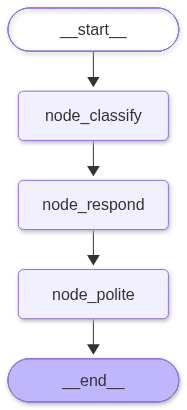

In [ ]:
# builder = StateGraph(State)
# builder.add_node("node_classify", classify)
# builder.add_node("node_respond", respond)
builder.add_node("node_polite", polite)            # 새 노드

# builder.add_edge(START, "node_classify")
# builder.add_edge("node_classify", "node_respond")
builder.add_edge("node_respond", "node_polite")    # 답변 → 인사말
builder.add_edge("node_polite", END)

print(list(builder.nodes))

graph = builder.compile()
print(graph.invoke({"question": "환불 규정 알려주세요"}))

print(graph)
graph

In [ ]:
# 엣지를 빼거나 바꿀 때: 처음부터 다시
# builder에는 엣지를 지우는 메소드가 없습니다.  node_respond → END가 그대로 남아 있습니다.

for x in  sorted(builder.edges):
    print(x)

('__start__', 'node_classify')
('node_classify', 'node_respond')
('node_polite', '__end__')
('node_respond', '__end__')
('node_respond', 'node_polite')


['node_classify', 'node_respond', 'node_polite']
{'question': '환불 규정 알려주세요', 'intent': '환불', 'answer': '환불 규정을 안내해 드리겠습니다. 바람길여행을 이용해 주셔서 감사합니다.'}


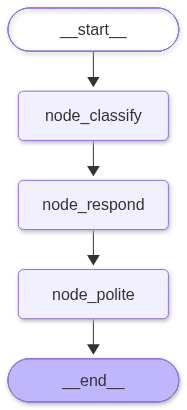

In [ ]:
# 처음부터 새로 만들기
# 노드추가 삭제, 엣지 변경이 없음으로 처음부터 다시 그려야함
# 함수의 내용을 변경해도 노드등록이 된 시점에서 함수가 빌드되어 있음으로 함수수정시 다시 빌드해야함.

builder = StateGraph(State)
builder.add_node("node_classify", classify)
builder.add_node("node_respond", respond)
builder.add_node("node_polite", polite)            # 새 노드

builder.add_edge(START, "node_classify")
builder.add_edge("node_classify", "node_respond")
builder.add_edge("node_respond", "node_polite")    # 답변 → 인사말
builder.add_edge("node_polite", END)

print(list(builder.nodes))

graph = builder.compile()
print(graph.invoke({"question": "환불 규정 알려주세요"}))

print(graph)
graph

In [ ]:
for x in  sorted(builder.edges):
    print(x)

('__start__', 'node_classify')
('node_classify', 'node_respond')
('node_polite', '__end__')
('node_respond', 'node_polite')


## Part2. 다중분기
                                          ┌→ node_refund  ─┐
                    START → node_classify ┼→ node_stay    ─┼→ node_polite → END
                                          └→ node_general ─┘
                        (갈라짐: 하나만 실행)            (모임)
       

In [44]:
def classify(state):
    q = state["question"]
    if "환불" in q or "취소" in q:
        return {"intent": "환불"}
    if "숙소" in q or "펜션" in q:
        return {"intent": "숙소"}
    return {"intent": "일반"}

def refund(state):
    return {"answer": "출발 5~9일 전 취소는 80%, 2~4일 전은 30% 환불됩니다."}

def stay(state):
    return {"answer": "계곡쉼 펜션은 반려동물 동반이 가능합니다."}

def general(state):
    return {"answer": "무엇을 도와드릴까요?"}

def polite(state):
    return {"answer": state["answer"] + " 바람길여행을 이용해 주셔서 감사합니다."}

In [45]:
from typing import Literal

def route(state) -> Literal["node_refund", "node_stay", "node_general"]:
    if state["intent"] == "환불":
        return "node_refund"
    if state["intent"] == "숙소":
        return "node_stay"
    return "node_general"

점선 3개(갈라짐)와 실선 3개(모임)개 출력. 
 
실선 화살표는 "항상 분기", 점선 화살표는 "조건에 따라 하나만 분기".
환불 → node_refund
숙소 → node_stay
일반 → node_general 



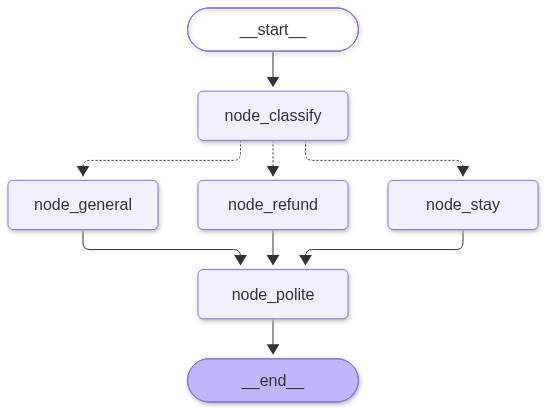

In [51]:
# 셀 그래프 만들기

from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    intent: str
    answer: str

builder = StateGraph(State)

# 노드 5개
builder.add_node("node_classify", classify)
builder.add_node("node_refund", refund)
builder.add_node("node_stay", stay)
builder.add_node("node_general", general)
builder.add_node("node_polite", polite)

# 시작
builder.add_edge(START, "node_classify")

# 갈라짐: classify 다음은 route가 정함
builder.add_conditional_edges("node_classify", route)

# 모임: 세 담당 모두 polite로
builder.add_edge("node_refund", "node_polite")
builder.add_edge("node_stay", "node_polite")
builder.add_edge("node_general", "node_polite")

# 끝
builder.add_edge("node_polite", END)

graph = builder.compile()

print('''점선 3개(갈라짐)와 실선 3개(모임)개 출력. \n 
실선 화살표는 "항상 분기", 점선 화살표는 "조건에 따라 하나만 분기".
환불 → node_refund
숙소 → node_stay
일반 → node_general 
''')
graph

### "출발 3일 전에 취소하면요?"
__start__ → node_classify → node_refund → node_polite → __end__
-               (intent: 환불)  (answer: 환불 규정)  (answer + 인사말)

### "강아지 되는 펜션 있어요?"
__start__ → node_classify → node_stay → node_polite → __end__

In [48]:
# 셀실행

for q in ["출발 3일 전에 취소하면요?", "강아지 되는 펜션 있어요?", "안녕하세요"]:
    print(graph.invoke({"question": q}))

{'question': '출발 3일 전에 취소하면요?', 'intent': '환불', 'answer': '출발 5~9일 전 취소는 80%, 2~4일 전은 30% 환불됩니다. 바람길여행을 이용해 주셔서 감사합니다.'}
{'question': '강아지 되는 펜션 있어요?', 'intent': '숙소', 'answer': '계곡쉼 펜션은 반려동물 동반이 가능합니다. 바람길여행을 이용해 주셔서 감사합니다.'}
{'question': '안녕하세요', 'intent': '일반', 'answer': '무엇을 도와드릴까요? 바람길여행을 이용해 주셔서 감사합니다.'}


### 지금 그래프 → RAG로 바꾸면

- 	RAG에서	하는 일
    - node_classify	질문 분류 (라우팅)	이 질문은 어느 자료를 찾아야 하나?
    - node_refund	규정 문서 검색	환불·취소 규정(T15, T16 등)에서 찾기
    - node_stay	숙소 문서 검색	숙소 자료(T06~T08)에서 찾기
    - node_general	검색 안 함	인사 같은 건 자료 없이 바로
    - node_polite	답변 생성	찾은 자료를 프롬프트에 넣고 LLM이 답하기

# Part3. 초간단 랭그래프 RAG
- travel_docs.csv

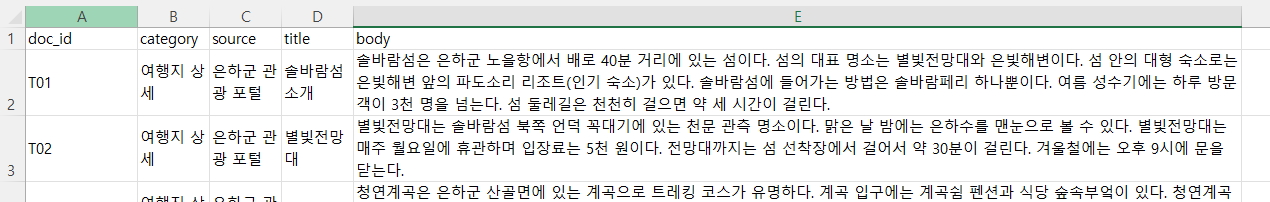

In [61]:
from dotenv import load_dotenv
load_dotenv()

import pandas as pd
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
docs = pd.read_csv("travel_docs.csv")

# 문서 번호 목록(예: ["T15", "T16"])을 받아서 각 문서의 제목과 본문을 하나의 글자로 이어 붙여 돌려준다.
# 어디서? 검색 노드가 이 함수로 자료를 만들어 context 칸에 적는다
def get_docs(doc_ids):
    text = ""
    for doc_id in doc_ids:
        row = docs[docs["doc_id"] == doc_id].iloc[0]     # 그 번호의 행 하나
        text += row["title"] + "\n" + row["body"] + "\n\n"
    return text



In [ ]:
# ### 그래프에 넣기 전에 확인
# 1. 데이터가 읽혔나? → docs.shape
# 2. 결과가 글자(str)인가? → 프롬프트에 그대로 넣을 수 있는지
# 3. 필요한 내용이 들어 있나? → 질문에 답할 문장이 자료에 있는지
# 4. 틀린 입력은? → 빈 목록, 없는 번호

# 확인용, 1. 데이터가 읽혔나? → docs.shape
print(docs.shape)
print(docs[:3])
print('-'*100)
print(docs[["doc_id", "title"]].head(3))

(22, 5)
  doc_id category     source    title  \
0    T01   여행지 상세  은하군 관광 포털  솔바람섬 소개   
1    T02   여행지 상세  은하군 관광 포털    별빛전망대   
2    T03   여행지 상세  은하군 관광 포털     청연계곡   

                                                body  
0  솔바람섬은 은하군 노을항에서 배로 40분 거리에 있는 섬이다. 섬의 대표 명소는 별...  
1  별빛전망대는 솔바람섬 북쪽 언덕 꼭대기에 있는 천문 관측 명소이다. 맑은 날 밤에는...  
2  청연계곡은 은하군 산골면에 있는 계곡으로 트레킹 코스가 유명하다. 계곡 입구에는 계...  
----------------------------------------------------------------------------------------------------
  doc_id    title
0    T01  솔바람섬 소개
1    T02    별빛전망대
2    T03     청연계곡


In [ ]:
# 확인용: 문서하나
# 2. 결과가 글자(str)인가? → 프롬프트에 그대로 넣을 수 있는지

result = get_docs(["T15"])
print(result)
print(type(result), len(result))

바람길여행 예약 취소·환불 규정
바람길여행 상품은 출발 10일 전까지 취소하면 전액 환불된다. 출발 5일에서 9일 전에 취소하면 80%, 2일에서 4일 전에 취소하면 30%를 환불하며, 출발 1일 전부터는 환불되지 않는다. 단, 숙소 비용은 해당 숙소 운영사의 취소 규정을 따른다. 환불은 결제 수단으로 영업일 기준 5일 안에 처리된다. 단체 예약은 별도 계약 조건을 따른다.


<class 'str'> 212


In [ ]:
# 확인용
# 숙소 검색 노드가 넣을 자료 (문서 3개)
# 3. 필요한 내용이 들어 있나? → 질문에 답할 문장이 자료에 있는지
print(get_docs(["T06", "T07", "T08"]))

# 에러용
# # 4. 틀린 입력은? → 빈 목록, 없는 번호
print(repr(get_docs([])))       # 빈 목록
get_docs(["T99"])               # 없는 번호

파도소리 리조트
파도소리 리조트는 솔바람섬 은빛해변 앞에 있는 리조트이다. 파도소리 리조트의 운영사는 해온호스피탈리티이다. 파도소리 리조트의 객실은 120개이며, 체크인은 오후 3시, 체크아웃은 오전 11시이다. 모든 객실에서 바다가 보이며 조식 뷔페가 유명하다. 리조트 로비에는 무료 자전거 보관소가 있다.

계곡쉼 펜션
계곡쉼 펜션은 청연계곡 입구에 있는 작은 펜션으로, 주인은 김산들이다. 계곡쉼 펜션의 객실은 8개이며 반려동물 동반 투숙이 가능하다. 객실마다 개별 바비큐 공간이 있다. 주말에는 예약이 빨리 마감된다.

노을스테이 호텔
노을스테이 호텔은 노을항에 있는 호텔로, 운영사는 해온호스피탈리티이다. 노을스테이 호텔에서 페리 터미널까지는 걸어서 5분이 걸린다. 옥상 라운지에서 노을을 보며 음료를 즐길 수 있다. 객실은 대부분 2인실이다.


''


IndexError: single positional indexer is out-of-bounds

In [ ]:
# State 작성
class State(TypedDict):
    question: str    # 질문
    intent: str      # 분류
    context: str     # 찾은 자료 ← 추가
    answer: str      # 답변

In [67]:
# 분류

def classify(state):
    q = state["question"]
    if "환불" in q or "취소" in q:
        return {"intent": "환불"}
    if "숙소" in q or "펜션" in q or "리조트" in q or "호텔" in q:
        return {"intent": "숙소"}
    return {"intent": "일반"}

# 검색 3개: 각자 다른 자료를 context 칸에 적음
# 실습용으로 get_docs에서 직접 문서 번호를 넣음

def search_policy(state):
    return {"context": get_docs(["T15", "T16", "T17"])}

def search_stay(state):
    return {"context": get_docs(["T06", "T07", "T08"])}

def no_search(state):
    return {"context": ""}

# 답변: question과 context를 읽어서 LLM이 답함
def generate(state):
    prompt = f"""당신은 바람길여행 상담원입니다.
[자료]에 있는 내용만으로 답하세요. 자료가 없거나 자료에 없는 내용이면 짧게 인사하거나 '자료에 없습니다'라고 답하세요.

[자료]
{state["context"]}

[질문]
{state["question"]}"""
    response = llm.invoke(prompt)
    return {"answer": response.content}

# 갈림길
def route(state) -> Literal["node_policy", "node_stay", "node_no_search"]:
    if state["intent"] == "환불":
        return "node_policy"
    if state["intent"] == "숙소":
        return "node_stay"
    return "node_no_search"

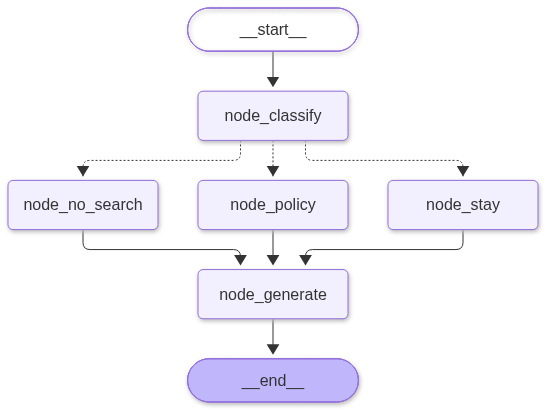

In [69]:
# 그래프

builder = StateGraph(State)

builder.add_node("node_classify", classify)
builder.add_node("node_policy", search_policy)
builder.add_node("node_stay", search_stay)
builder.add_node("node_no_search", no_search)
builder.add_node("node_generate", generate)

builder.add_edge(START, "node_classify")
builder.add_conditional_edges("node_classify", route)
builder.add_edge("node_policy", "node_generate")
builder.add_edge("node_stay", "node_generate")
builder.add_edge("node_no_search", "node_generate")
builder.add_edge("node_generate", END)

graph = builder.compile()
graph 

In [70]:
for q in ["출발 3일 전에 취소하면 환불돼요?", "강아지랑 묵을 수 있는 숙소 있어요?", "안녕하세요"]:
    result = graph.invoke({"question": q})
    print("질문:", q)
    print("분류:", result["intent"])
    print("답변:", result["answer"])
    print()

질문: 출발 3일 전에 취소하면 환불돼요?
분류: 환불
답변: 출발 3일 전에 취소하면 30% 환불됩니다.

질문: 강아지랑 묵을 수 있는 숙소 있어요?
분류: 숙소
답변: 계곡쉼 펜션은 반려동물 동반 투숙이 가능합니다.

질문: 안녕하세요
분류: 일반
답변: 안녕하세요! 어떻게 도와드릴까요?



# 그래프로 작성시 좋은점

-  흐름을 LLM이 정한다 (에이전트)
    - 질문만 주면 LLM이 "가격 검색 → 환불 계산 → 답변"을 스스로 정합니다.
    - 질문이 바뀌면 순서도, 도구를 쓰는 횟수도 바뀝니다. 코드에는 순서를 적지 않습니다.

- 중간에 멈췄다가, 나중에 이어서 실행 (사람 승인)
    - 실제로 환불을 처리하기 직전에 그래프가 멈추고 상담원 승인을 기다립니다.
    - 상담원이 다음 날 승인해도 멈춘 지점부터 이어서 실행됩니다. 손님 정보도, 계산 결과도 그대로 남아 있습니다.
    - 일반 코드로 하려면 중간 상태 저장, 어디까지 했는지 기록, 재개 로직을 전부 직접 짜야 합니다.

- 지난 단계로 되돌리기 (시간 여행)
    - "아까 계산 단계에서 가격을 잘못 넣었네" → 그 단계로 돌아가서 값만 고쳐 다시 실행합니다.


- [샘플] 
    - 손님: 솔바람섬 별빛 2박3일 5일 전 취소할게요. 환불해 주세요.
        - [AI] search_docs("별빛 2박3일") → 39만 원
        - [AI] calc_refund(390000, 5) → 312,000원
        - [AI] process_refund(312,000원) 실행하려 함
        
        - ⏸  그래프 멈춤: 상담원 승인 대기 중 (thread_id = guest_kim)
        
        - ──── (다음 날, 다른 셀에서) ───
        - 상담원: 승인
        - ▶  멈춘 지점부터 재개 → 환불 처리 완료 → 손님에게 안내


## Part4.Corrective RAG (CRAG)

**Corrective Retrieval-Augmented Generation (교정형 RAG)**

검색된 문서의 적합성을 평가하고, 검색 결과가 부정확하거나 부족하면 교정·재검색한 후 LLM에 전달하는 RAG 방식.

### 1. 일반 RAG와 차이

| 구분 | 일반 RAG | Corrective RAG |
|---|---|---|
| 문서 검색 | 벡터DB 검색 | 벡터DB 검색 |
| 검색 결과 평가 | 선택적 | 필수 |
| 부적합 문서 | 그대로 사용 가능 | 제거 또는 재검색 |
| 추가 검색 | 별도 구현 | 필요시 웹 검색 등 수행 |
| 특징 | 단순하고 빠름 | 답변 근거의 신뢰성 향상 |

### 2. 처리 과정

1. **Retrieve**: FAISS, OpenSearch 등에서 관련 문서 검색
2. **Evaluate**: 검색 결과의 적합성 평가
3. **Correct**: 평가 결과에 따라 교정
   - **Correct**: 적합한 문서 정제 후 사용
   - **Incorrect**: 부적합한 결과를 버리고 재검색
   - **Ambiguous**: 기존 검색 결과와 추가 검색 결과 활용
4. **Generate**: 교정된 문서를 LLM에 전달하여 답변 생성

### 3. 핵심 개념

- **Reranking**: 검색 문서의 순위를 조정
- **Corrective RAG**: 검색 결과를 사용할지 판단하고 필요하면 재검색
- **Self-RAG**: 검색 필요성과 생성된 답변까지 자기 평가

**핵심:** 일반 RAG에 검색 결과 평가(Evaluator)와 조건부 교정(Correction) 단계를 추가한 방식.

#### [예시]
일반 RAG는 **검색이 엉뚱한 자료를 가져와도 그대로 답합니다.** 손님은 이렇게 묻습니다.

> "애들이랑 밤에 반짝이는 벌레 보러 가고 싶어요. 언제 가면 돼요?"

자료에는 "반딧불 축제"라고 적혀 있고, "반짝이는 벌레"라는 말은 없습니다.

검색이 빗나가면 LLM은 엉뚱한 자료로 답하거나 "자료에 없습니다"라고 합니다.

그래서 **자료가 맞는지 먼저 확인하고, 아니면 검색어를 바꿔 다시 찾습니다.**

### 설계

```text
START → node_retrieve → node_grade ─┬→ node_generate → END
             ↑                      │   (자료가 맞음 또는 재검색 횟수 초과)
             │                      │
             └──── node_rewrite ←───┘
                    (자료가 안 맞음 → 검색어 바꾸기)
```

| 노드 | 하는 일 | 채우는 칸 |
|---|---|---|
| `node_retrieve` | 벡터DB 검색 | `context` |
| `node_grade` | 자료로 질문에 답할 수 있는지 LLM이 채점 (yes/no) | `relevant` |
| `node_rewrite` | 검색어를 자료에 맞는 말로 바꿈 | `search_query`, `retry` |
| `node_generate` | 자료로 답변 | `answer` |


In [ ]:
!pip install -q langgraph langchain-openai pandas python-dotenv

In [101]:
from dotenv import load_dotenv
load_dotenv()

import pandas as pd
from typing import TypedDict, Literal
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser, JsonOutputParser

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [102]:
# 벡터db만들기

docs = pd.read_csv("travel_docs.csv")

documents = []
for _, row in docs.iterrows():
    documents.append(Document(
        page_content=row["title"] + "\n" + row["body"],
        metadata={"doc_id": row["doc_id"]},
    ))

vectorstore = InMemoryVectorStore.from_documents(documents, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

In [103]:
# 체인3개

# ① 채점 체인: 자료로 답할 수 있나? → JSON
grade_prompt = ChatPromptTemplate.from_template(
    """아래 [자료]로 [질문]에 답할 수 있는지 판정하세요.
JSON으로만 답하세요. 형식: {{"relevant": "yes" 또는 "no", "reason": "판단 이유 한 문장"}}

[자료]
{context}

[질문]
{question}"""
)
grade_chain = grade_prompt | llm | JsonOutputParser()

# ② 검색어 다시 쓰기 체인
# 자료 목차: 문서 제목 22개
titles = "\n".join("- " + t for t in docs["title"])

rewrite_prompt = ChatPromptTemplate.from_template(
    """손님 질문으로 여행 자료를 검색했지만 맞는 자료를 찾지 못했습니다.
아래 [자료 목차]를 보고, 질문과 관련 있는 자료의 제목에 나오는 말로 검색어를 다시 쓰세요.
손님이 쓴 일상적인 표현은 목차에 있는 정식 이름으로 바꾸세요.
(예: 강아지 → 반려동물, 배 → 페리)
이전 검색어와 다른 말을 쓰세요. 검색어 한 줄만 출력하세요.

[자료 목차]
{titles}

[손님 질문]
{question}

[이전 검색어]
{search_query}"""
)
rewrite_chain = rewrite_prompt | llm | StrOutputParser()

# ③ 답변 체인
answer_prompt = ChatPromptTemplate.from_template(
    """당신은 바람길여행 상담원입니다. [자료]에 있는 내용만으로 답하세요.
자료로 답할 수 없으면 '자료에 없습니다'라고 답하세요.

[자료]
{context}

[질문]
{question}"""
)
answer_chain = answer_prompt | llm | StrOutputParser()

In [104]:
# state
class State(TypedDict):
    question: str        # 손님 원래 질문 (바뀌지 않음)
    search_query: str    # 검색어 (다시 쓰면 바뀜)
    context: str         # 검색한 자료
    relevant: str        # 채점 결과 "yes" / "no"
    retry: int           # 검색어를 다시 쓴 횟수
    answer: str          # 최종 답변

In [105]:
# 노드함수
def retrieve(state):
    found = retriever.invoke(state["search_query"])
    print(f"[retrieve] 검색어: {state['search_query']} → 찾은 문서: {[d.metadata['doc_id'] for d in found]}")
    return {"context": "\n\n".join(d.page_content for d in found)}

def grade(state):
    result = grade_chain.invoke({"context": state["context"], "question": state["question"]})
    print(f"[grade] {result['relevant']} - {result['reason']}")
    return {"relevant": result["relevant"]}

def rewrite(state):
    new_query = rewrite_chain.invoke({
        "titles": titles,                       # ← 목차 넣기 (새로 추가)
        "question": state["question"],
        "search_query": state["search_query"],
    })
    print(f"[rewrite] 새 검색어: {new_query}")
    return {"search_query": new_query, "retry": state["retry"] + 1}

def generate(state):
    answer = answer_chain.invoke({"context": state["context"], "question": state["question"]})
    print(f"[generate] {answer}")
    return {"answer": answer}

In [106]:
# 분기
MAX_RETRY = 2    # 검색어는 최대 2번까지만 다시 씀

def after_grade(state) -> Literal["node_generate", "node_rewrite"]:
    if state["relevant"] == "yes":
        return "node_generate"        # 자료가 맞음 → 답변
    if state["retry"] >= MAX_RETRY:
        return "node_generate"        # 충분히 찾아봤음 → 답변 ('자료에 없습니다')
    return "node_rewrite"             # 자료가 안 맞음 → 검색어 바꾸기

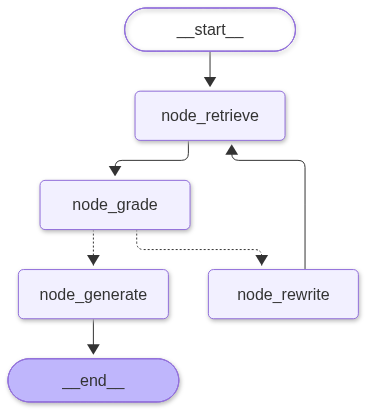

In [107]:
# 셀그래프
builder = StateGraph(State)

builder.add_node("node_retrieve", retrieve)
builder.add_node("node_grade", grade)
builder.add_node("node_rewrite", rewrite)
builder.add_node("node_generate", generate)

builder.add_edge(START, "node_retrieve")
builder.add_edge("node_retrieve", "node_grade")
builder.add_conditional_edges("node_grade", after_grade)
builder.add_edge("node_rewrite", "node_retrieve")
builder.add_edge("node_generate", END)

graph = builder.compile()
graph

In [108]:
# 실행도우미
def ask(question):
    # 처음에는 검색어 = 질문, 다시 쓴 횟수 = 0
    return graph.invoke({"question": question, "search_query": question, "retry": 0})

In [ ]:
# 실행 1: 일상어 질문 → 1차 검색 실패 → 채점 no → 검색어를 목차의 말("반딧불")로 바꿔 재검색 → 성공
r = ask("애들이랑 밤에 반짝이는 벌레 보러 가고 싶어요. 언제 가면 돼요?")
print("최종:", r["answer"], "| 재검색:", r["retry"])

[retrieve] 검색어: 애들이랑 밤에 반짝이는 벌레 보러 가고 싶어요. 언제 가면 돼요? → 찾은 문서: ['T18', 'T06', 'T02']
[grade] no - 주어진 자료에는 반짝이는 벌레 관찰에 대한 정보가 포함되어 있지 않기 때문입니다.
[rewrite] 새 검색어: 반딧불숲과 반딧불 축제 언제 가면 돼요?
[retrieve] 검색어: 반딧불숲과 반딧불 축제 언제 가면 돼요? → 찾은 문서: ['T04', 'T13', 'T02']
[grade] yes - 반딧불숲에서 매년 6월에 반딧불 축제가 열리며, 축제 기간에 야간 탐방이 가능하기 때문이다.
[generate] 반딧불숲에서 반딧불 축제가 매년 6월에 열립니다. 축제 기간 동안 야간 탐방은 사전 예약제로 운영되니, 6월에 방문하시면 됩니다.
최종: 반딧불숲에서 반딧불 축제가 매년 6월에 열립니다. 축제 기간 동안 야간 탐방은 사전 예약제로 운영되니, 6월에 방문하시면 됩니다. | 재검색: 1


In [110]:
# 실행2: 자료에 정말 없을 때
r = ask("솔바람섬에서 와이파이 돼요?")
print("최종:", r["answer"], "| 재검색:", r["retry"])

[retrieve] 검색어: 솔바람섬에서 와이파이 돼요? → 찾은 문서: ['T01', 'T19', 'T11']
[grade] no - 자료에 솔바람섬에서 와이파이에 대한 정보가 포함되어 있지 않기 때문입니다.
[rewrite] 새 검색어: 솔바람섬 소개
[retrieve] 검색어: 솔바람섬 소개 → 찾은 문서: ['T01', 'T19', 'T11']
[grade] no - 자료에 솔바람섬에서 와이파이에 대한 정보가 포함되어 있지 않기 때문입니다.
[rewrite] 새 검색어: 솔바람섬 여행 FAQ
[retrieve] 검색어: 솔바람섬 여행 FAQ → 찾은 문서: ['T19', 'T01', 'T18']
[grade] no - 자료에 솔바람섬의 와이파이 여부에 대한 정보가 포함되어 있지 않음
[generate] 자료에 없습니다.
최종: 자료에 없습니다. | 재검색: 2
